### 1. IMPORTING THE RELEVANT LIBRARIES ###

In [40]:
import scipy.integrate as scipy_integrate
import scipy.special as special
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.colors import TwoSlopeNorm

In [41]:
plt.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "font.family": "serif",
})

### 2. GAUSSIAN ENERGY EXPRESSION ###

In [ ]:
# Gaussian energy function
def Gaussian(mu, U, data, J):
    d = 3 # We are considering a 3D cubic lattice, so d = 3.
    # Integrals are precomputed and stored in the data dictionary
    gamma = data["gamma"]
    alpha = data["alpha"]
    first = data["first"]

    Jz = 2*d*J

    # Minimizing density rho0 based on the Gaussian ansatz
    rho0 = (mu + Jz)/U -2*np.array(gamma) - np.array(alpha)

    # Energy expression based on the Gaussian ansatz
    E = ( 
        J/U* np.array(first) 
        - 1/U*(mu+Jz)*(rho0 + np.array(gamma)) 
        + 1/2*(rho0**2 + 2*(np.array(gamma))**2 + (np.array(alpha))**2 
        + 2*rho0*(2*np.array(gamma) + np.array(alpha) )  )
    )

    return E

### 3. APPROXIMATION OF THE INTEGRALS ###

In [43]:
# Approximation of the integrals by a sum over a grid of points in the Brillouin zone.

N = 60 # Grid size

p = np.linspace(-np.pi,np.pi,N)
P1,P2,P3 = np.meshgrid(p,p,p,indexing='ij')

dV = (2*np.pi/(N-1))**3

def integrals(J, U):

    eps = J/U*2*((1-np.cos(P1))
         +(1-np.cos(P2))
         +(1-np.cos(P3)))

    # Parameters for the lambda values
    lamda1 = np.linspace(0, 300, 500)
    lamda2 = np.linspace(0, 300, 500)

    gamma = []
    alpha = []
    first = []

    l1_list = []
    l2_list = []

    # Loop over the lambda values and compute the integrals
    for l1 in lamda1:
        for l2 in lamda2:
            if abs(l2) < l1: # Impose the condition |l2| < l1 to ensure the square root is real
                denom = np.sqrt((eps+l1)**2-l2**2)
                gamma_expression = 0.5 *  ((eps + l1)/denom - 1)
                alpha_expression = - 0.5  * l2/denom
                first_expression = 0.5 * eps * ((eps + l1)/denom - 1)
                gamma.append(np.sum(gamma_expression)*dV/(2*np.pi)**3)
                alpha.append(np.sum(alpha_expression)*dV/(2*np.pi)**3)
                first.append(np.sum(first_expression)*dV/(2*np.pi)**3)
                l1_list.append(l1)
                l2_list.append(l2)

    return {
    "gamma": gamma,
    "alpha": alpha,
    "first": first,
    "l1_list": l1_list,
    "l2_list": l2_list  
    }

### 4. PROOF OF EXISTENCE OF MINIMIZERS ###

In [ ]:
U = 10

mu_vals = np.linspace(0, 3*U, 100)

Jc = U/6 * 1/(np.sqrt(1+1) + np.sqrt(1))**2

J_vals = np.linspace(0, 4*Jc, 100)

d = 3

Energy_min = np.zeros((len(J_vals), len(mu_vals)))
Energy_0 = np.zeros((len(J_vals), len(mu_vals)))


for i, J in enumerate(J_vals):

    data = integrals(J, U)

    for j, mu in enumerate(mu_vals):

        Energy = np.min(Gaussian(mu, U, data, J))

        Energy_min[i, j] = Energy

        Energy0 = -1/2 * (mu/U + 2*d*J/U)**2

        Energy_0[i, j] = Energy0

        if Energy > Energy0:

            print('problem')
            print('J =', J, 'mu =', mu)

            print('lamda1 =', data["l1_list"][j],
                'lamda2 =', data["l2_list"][j])

Energy_diff = Energy_min - Energy_0

KeyboardInterrupt: 

NameError: name 'Energy_diff' is not defined

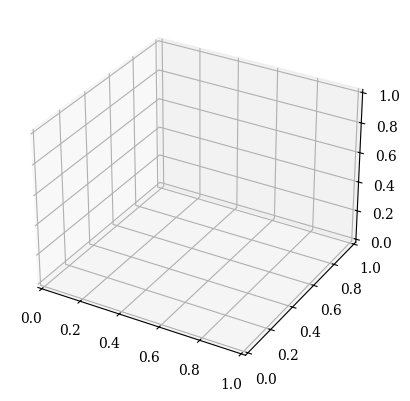

In [45]:
fig = plt.figure()
ax = plt.axes(projection='3d')
surf = ax.plot_surface(mu_vals, J_vals, Energy_diff, cmap="coolwarm", linewidth=0, antialiased=False)
ax.set_xlabel(r'$\mu$ ')
ax.set_ylabel(r'$J$')
ax.set_zlabel(r'$\bar{\varepsilon}_{min} - \bar{\varepsilon}_0$')
plt.title(r'Energy difference $\bar{\varepsilon}_{min} - \bar{\varepsilon}_0$')
fig.colorbar(surf, shrink=0.5, aspect=7)
plt.show()


### 5. GUTZWILLER ENERGY EXPRESSIONS ###

In [46]:
# Function which determines the value of n0 based on the value of mu/U when theta = 0
def n0_func(mu, U): 
    term = mu/U + 1/2
    if term >= int(term) + 1/2: 
        return int(term) + 1
    else:
        return int(term)

In [47]:
# Gutzwiller energy function when theta = 0
def Gutzwiller_E0(mu, J, U):
    n0 = n0_func(mu, U)
    dmu = mu/U - (n0 - 0.5)
    E_Gutzwiller_E0 = -dmu*n0 - n0**2/2
    return {"Gutzwiller_E": E_Gutzwiller_E0}

In [48]:
# Gutzwiller energy function for small theta
def Gutzwiller_var2(mu, J, U):
    # We calculate the Gutzwiller energy for small psi. We loop over different theta values to find the lowest energy.
    theta_vals = np.linspace(-np.pi/5, np.pi/5, 100)

    psi_list = []

    Gutzwiller_E_var_list = []
    d = 3
    Jz = 2*d*J/U
    
    sigma_list = []
    a_list = []
    b_list = []

    for theta in theta_vals:
        n0 = n0_func(mu, U)
        dmu = mu/U-(n0 - 0.5)
        sigma = 1/2* np.arctan((4*dmu + Jz*(1+np.cos(0)))/(2*Jz*(1+np.cos(0))*np.sqrt((n0+1)*n0)))

        K = 1/2*(np.sqrt(n0+1)*np.cos(np.pi/4-sigma) + np.sqrt(n0)*np.sin(np.pi/4-sigma))
        a = ( 1/4*(1/2 - dmu*np.sin(2*sigma)) - Jz/2*(n0 + np.sqrt((n0+1)*n0)*np.cos(2*sigma) + 1/2*(1+np.sin(2*sigma))))/K**2
        b = (2*Jz*(n0 + np.sqrt((n0+1)*n0)*np.cos(2*sigma) + 1/2*(1+np.sin(2*sigma))) - 1/4*(1/2 + dmu*np.sin(2*sigma)) )/K**4

        psi = K*np.sin(theta)

        E = a*psi**2 + b*psi**4 - n0**2/2 - dmu*n0

        Gutzwiller_E_var_list.append(E)

        psi_list.append(psi)

        sigma_list.append(sigma)
        a_list.append(a)
        b_list.append(b)
    
    psi_list = np.array(psi_list)
    sigma_list = np.array(sigma_list)
    a_list = np.array(a_list)
    b_list = np.array(b_list)

    Gutzwiller_E_var_list = np.array(Gutzwiller_E_var_list)
    min = np.min(Gutzwiller_E_var_list)
    for i in range(len(Gutzwiller_E_var_list)):
        if Gutzwiller_E_var_list[i] == min:
            theta_min = theta_vals[i]
            psi_min = psi_list[i]
            sigma_min = sigma_list[i]
            a_min = a_list[i]
            b_min = b_list[i]

    Gutzwiller_E_var = min
    return {
        "Gutzwiller_E": Gutzwiller_E_var,
        "psi_min": psi_min,
        "theta_min": theta_min,
        "sigma_min": sigma_min,
        "dmu" : dmu,
        "a": a_min,
        "b": b_min,
    }

In [49]:

# Gutzwiller energy function for a general theta
def Gutzwiller_general(mu, J, U):
    theta_vals = np.linspace(0, 2*np.pi, 300)
    sigma_vals = np.linspace(0, 2*np.pi, 300)
    n0_vals = np.arange(0, 4)

    d = 3
    Jz = 2*d*J/U

    theta_list = []

    Gutzwiller_E = []

    # We minimize the Gutzwiller energy over n0, sigma, and theta to find the lowest energy configuration.
    for n0 in n0_vals:
        for sigma in sigma_vals:
            for theta in theta_vals:
                dmu = mu/U - (n0 - 0.5)

                E = np.sin(theta/2)**2*(1/2 - dmu*np.sin(2*sigma)) - Jz/4*np.sin(theta)**2*(n0 + np.sqrt((n0+1)*n0)*np.cos(2*sigma) + 1/2*(1+np.sin(2*sigma))) -dmu*n0 - 1/2*n0**2

                Gutzwiller_E.append(E)

                theta_list.append(theta)


    
    return {
        "Gutzwiller_E": Gutzwiller_E,
        "theta_list": theta_list,
    }

### 6. ENERGY COMPARISON BETWEEN GAUSSIAN AND GUTZWILLER ###

In [50]:
# Function which finds the lowest energy between Gutzwiller and Gaussian for different values of J and U, for fixed mu, rho0 and n0.
def lowest_energy_J_mu(J_vals, mu_vals, U, Gutzwiller_function, Gauss_data):
    Gutzwiller_lowest= []
    Gauss_lowest= []
    mu_Gauss= []
    mu_Gutzwiller= []
    J_Gauss = []
    J_Gutzwiller= []
    mu_crit= []
    J_crit= []
    d = 3 
    Jc_over_U = 1/(2*d)*1/(np.sqrt(2)+1)**2
    
    for i, J in enumerate(J_vals):
        for j, mu in enumerate(mu_vals):
            Gutz_data = Gutzwiller_function(mu, J, U)
            E_Gutzwiller = np.min(Gutz_data["Gutzwiller_E"])
            E_Gauss=np.min(Gauss_data[i, j])
            if abs(E_Gauss - E_Gutzwiller) < 1e-2/U:
                mu_crit.append(mu/U)
                J_crit.append((J/U)/Jc_over_U)
            if E_Gauss < E_Gutzwiller:
                Gauss_lowest.append(E_Gauss)
                mu_Gauss.append(mu/U)
                J_Gauss.append((J/U)/Jc_over_U)
            if E_Gauss >= E_Gutzwiller:
                Gutzwiller_lowest.append(E_Gutzwiller)
                mu_Gutzwiller.append(mu/U)
                J_Gutzwiller.append((J/U)/Jc_over_U)
    return Gutzwiller_lowest, Gauss_lowest, mu_Gutzwiller, mu_Gauss, J_Gutzwiller, J_Gauss, mu_crit, J_crit

In [ ]:
# We define the parameters for the calculations. We set U = 1 and create a range of mu values from 0 to 3*U, and a range of J values from 1e-10 to 4*Jc
U = 1
mu_vals = np.linspace(0, 3*U, 150)
Jc = U/6*1/(np.sqrt(1+1)+np.sqrt(1))**2

J_vals = np.linspace(1e-10,4*Jc,150)

Gaussian_data = np.zeros((len(J_vals), len(mu_vals)))

# We find the Gaussian energy for each combination of J and mu, and store the results in the Gaussian_data array.
for i, J in enumerate(J_vals):
    Integrals = integrals(J, U)
    for j, mu in enumerate(mu_vals):
        Gaussian_data[i, j] = np.min(Gaussian(mu, U, Integrals, J))

KeyboardInterrupt: 

In [ ]:
# We find the lowest energy between Gutzwiller and Gaussian for each combination of J and mu, using the three different Gutzwiller functions.
E0_J_mu = lowest_energy_J_mu(J_vals, mu_vals, U, Gutzwiller_E0, Gaussian_data)
Small_psi_J_mu = lowest_energy_J_mu(J_vals, mu_vals, U, Gutzwiller_var2, Gaussian_data)
General_J_mu = lowest_energy_J_mu(J_vals, mu_vals, U, Gutzwiller_general, Gaussian_data)

<Figure size 640x480 with 0 Axes>

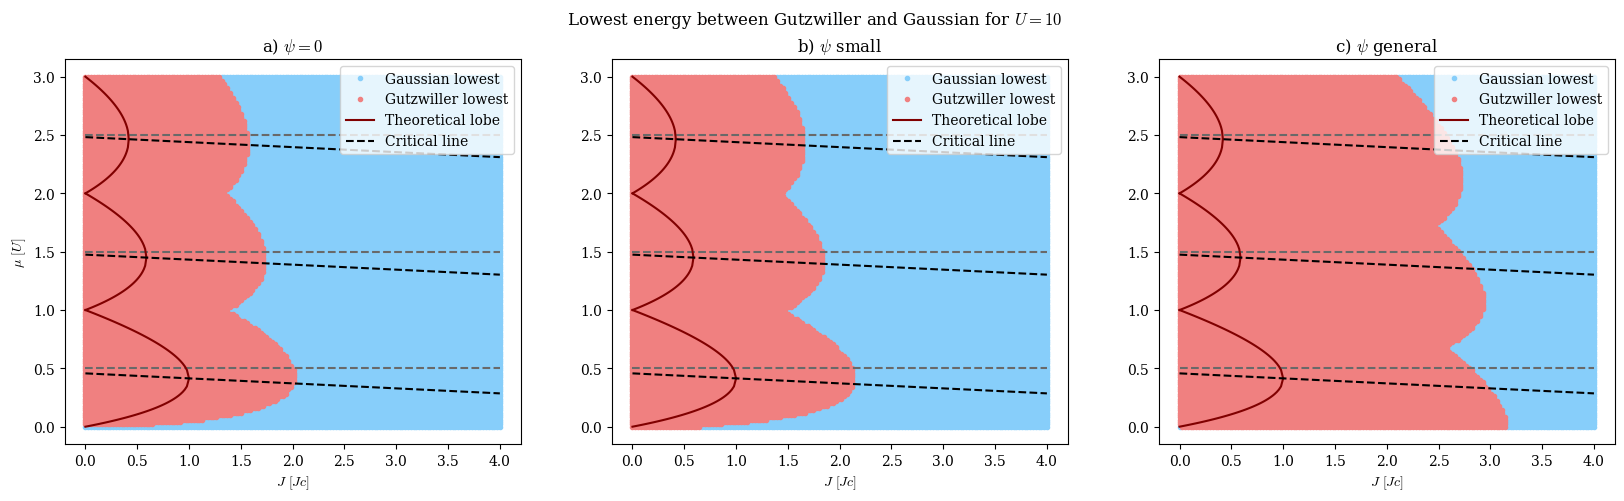

In [53]:
fig = plt.figure()
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20,5))
ax1.plot( E0_J_mu[5], E0_J_mu[3], '.', label='Gaussian lowest', color='lightskyblue')
ax1.plot( E0_J_mu[4], E0_J_mu[2], '.', label='Gutzwiller lowest', color='lightcoral')
ax2.plot( Small_psi_J_mu[5], Small_psi_J_mu[3], '.', label='Gaussian lowest', color='lightskyblue')
ax2.plot( Small_psi_J_mu[4], Small_psi_J_mu[2], '.', label='Gutzwiller lowest', color='lightcoral')
ax3.plot( General_J_mu[5], General_J_mu[3], '.', label='Gaussian lowest', color='lightskyblue')
ax3.plot( General_J_mu[4], General_J_mu[2], '.', label='Gutzwiller lowest', color='lightcoral')
ax1.hlines(y=0.5, xmin=0, xmax=4, color='dimgrey', linestyle='--')
ax1.hlines(y=1.5, xmin=0, xmax=4, color='dimgrey', linestyle='--')
ax1.hlines(y=2.5, xmin=0, xmax=4, color='dimgrey', linestyle='--')
ax2.hlines(y=0.5, xmin=0, xmax=4, color='dimgrey', linestyle='--')
ax2.hlines(y=1.5, xmin=0, xmax=4, color='dimgrey', linestyle='--')
ax2.hlines(y=2.5, xmin=0, xmax=4, color='dimgrey', linestyle='--')
ax3.hlines(y=0.5, xmin=0, xmax=4, color='dimgrey', linestyle='--')
ax3.hlines(y=1.5, xmin=0, xmax=4, color='dimgrey', linestyle='--')
ax3.hlines(y=2.5, xmin=0, xmax=4, color='dimgrey', linestyle='--')

# Theoretical lobes of the phase diagram
axes =[ax1, ax2, ax3]
n = np.array([1, 2, 3])
for j in range(3):
    for i in n:
        J_c = (np.sqrt(i+1)+np.sqrt(i))**(-2)-0.00000001
        J_c1 =(np.sqrt(1+1)+np.sqrt(1))**(-2) 
        J_max = 4*J_c1
        J = np.linspace(0, J_c)
        J_n = np.linspace(0, J_max)
        n_0 = np.ones(len(J_n))*i-0.5
        dmu_plus = 1/2*(- J + np.sqrt(1-2*J*(1+2*i)+J**2))
        dmu_minus = 1/2*(- J - np.sqrt(1-2*J*(1+2*i)+J**2))
        dmu_n = - 1/4*(J_n + (np.sqrt(i+1) + np.sqrt(i))**(-2))
        dmu_c = -1/2*J_c+i-0.5
        if i == 1:
            axes[j].plot(J/J_c1, dmu_plus + i-0.5, color = 'maroon', label = 'Theoretical lobe')
            axes[j].plot(J/J_c1, dmu_minus + i-0.5, color = 'maroon')
            axes[j].plot(J_n/J_c1, dmu_n + i-0.5, '--', color = 'black', label = 'Critical line')
        else:
            axes[j].plot(J/J_c1, dmu_plus + i-0.5, color = 'maroon')
            axes[j].plot(J/J_c1, dmu_minus + i-0.5, color = 'maroon')
            axes[j].plot(J_n/J_c1, dmu_n + i-0.5, '--', color = 'black')


ax1.set_ylabel(r'$\mu$ $[U]$')
fig.suptitle(r'Lowest energy between Gutzwiller and Gaussian for $U = 10$')
ax1.set_title(r'a) $\psi = 0$')
ax2.set_title(r'b) $\psi$ small')
ax3.set_title(r'c) $\psi$ general')
ax1.set_xlabel(r'$J$ $[Jc]$')
ax2.set_xlabel(r'$J$ $[Jc]$')
ax3.set_xlabel(r'$J$ $[Jc]$')
ax1.legend()
ax2.legend()
ax3.legend()

### 7. COLOR MAP OF THE ENERGY DIFFERENCE BETWEEN GAUSSIAN AND GUTZWILLER ###

In [54]:
def Gutz_Energies(Gutzwiller_function, mu_vals, J_vals, U):
    Gutzwiller_Energies = []
    for J in J_vals:
        for mu in mu_vals:
            Gutzwiller_data = Gutzwiller_function(mu, J, U)
            Gutzwiller_Energies.append(np.min(Gutzwiller_data["Gutzwiller_E"]))
    return np.array(Gutzwiller_Energies)

mu_vals = np.linspace(0, 3*U, 150)
J_vals = np.linspace(1e-10,4*Jc,150)
Gutz_energy_E0 = Gutz_Energies(Gutzwiller_E0, mu_vals, J_vals, U)
Gutz_energy_var2 = Gutz_Energies(Gutzwiller_var2, mu_vals, J_vals, U)
Gutz_energy_general = Gutz_Energies(Gutzwiller_general, mu_vals, J_vals, U)

KeyboardInterrupt: 

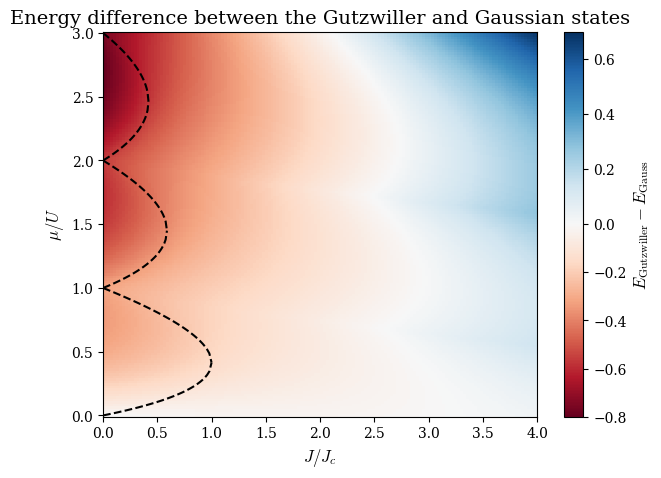

In [55]:
# Color plot of the energy difference between Gutzwiller and Gaussian states for the general Gutzwiller function
plt.figure(figsize=(7,5))

U=1
Energy_difference = Gutz_energy_general.reshape(len(J_vals),len(mu_vals)) - Gaussian_data
Energy_diff_percent = Energy_difference / Gaussian_data*100
Gutz_vs_Gauss = Gutz_energy_general.reshape(len(J_vals),len(mu_vals))/Gaussian_data

J_grid, mu_grid = np.meshgrid(J_vals, mu_vals, indexing='ij')

Jc = U/6*1/(np.sqrt(1+1)+np.sqrt(1))**2

J_plot = J_grid / (Jc)
mu_plot = mu_grid / U

# Center the colormap at zero
norm = TwoSlopeNorm(
    vmin=-0.8,
    vcenter=0,
    vmax=0.7
)

plt.pcolormesh(
    J_plot,
    mu_plot,
    Energy_difference,
    shading='auto',
    cmap='RdBu',
    norm=norm
)

cbar = plt.colorbar(
    label=r'$E_{\rm Gutzwiller} - E_{\rm Gauss}$'
)

cbar.set_label(
    r'$E_{\rm Gutzwiller} - E_{\rm Gauss}$',
    fontsize=12
)
# Theoretical lobes of the phase diagram
n = np.array([1, 2, 3])
for i in n:
    J_c = (np.sqrt(i+1)+np.sqrt(i))**(-2)-0.00000001
    J_c1 =(np.sqrt(1+1)+np.sqrt(1))**(-2) 
    J_max = 4*J_c1
    J = np.linspace(0, J_c)
    J_n = np.linspace(0, J_max)
    n_0 = np.ones(len(J_n))*i-0.5
    dmu_plus = 1/2*(- J + np.sqrt(1-2*J*(1+2*i)+J**2))
    dmu_minus = 1/2*(- J - np.sqrt(1-2*J*(1+2*i)+J**2))
    dmu_n = - 1/4*(J_n + (np.sqrt(i+1) + np.sqrt(i))**(-2))
    dmu_c = -1/2*J_c+i-0.5
    if i == 1:
        plt.plot(J/J_c1, dmu_plus + i-0.5, color = 'black', label = 'Phase transition', linestyle ='--')
        plt.plot(J/J_c1, dmu_minus + i-0.5, color = 'black', linestyle ='--')
    else:
        plt.plot(J/J_c1, dmu_plus + i-0.5, color = 'black', linestyle ='--')
        plt.plot(J/J_c1, dmu_minus + i-0.5, color = 'black', linestyle ='--')


plt.xlabel(r'$J/J_c$', fontsize =12)
plt.ylabel(r'$\mu/U$', fontsize =12)
plt.title(r'Energy difference between the Gutzwiller and Gaussian states', fontsize =14)
plt.xlim(0, 4)
plt.show()

### 8. GAUSSIAN ENERGY IN THE LIMIT OF THE CHEMICAL POTENTIAL GOING TO ZERO ###

In [ ]:
# We approximate the integral in the function for C_3 using Riemann sums
J = 1
N = 200

p = np.linspace(-np.pi,np.pi,N)
P1,P2,P3 = np.meshgrid(p,p,p,indexing='ij')

eps = J*2*((1-np.cos(P1))
         +(1-np.cos(P2))
         +(1-np.cos(P3)))

dV = (2*np.pi/(N-1))**3

C = np.sum(1/eps)*dV/(2*np.pi)**3


In [35]:
# We find the Gaussian energy for small mu, and compare it to the theoretical prediction for the energy in this limit
J = 1
U = 1
data = integrals(J, U)
mu_vals = np.linspace(0, 0.01, 60)
E_theory_list = []
E_Gauss_list = []
for mu in mu_vals:
    a_s = 1/(4*np.pi)*U/(2 + U*C) # The scattering length a_s is defined in terms of the interaction strength U and the integral C
    E_theory = (- mu**2/(16*np.pi*a_s) )/U
    E_Gauss = np.min(E(mu-6, U, data, J))
    E_theory_list.append(E_theory)
    E_Gauss_list.append(E_Gauss)

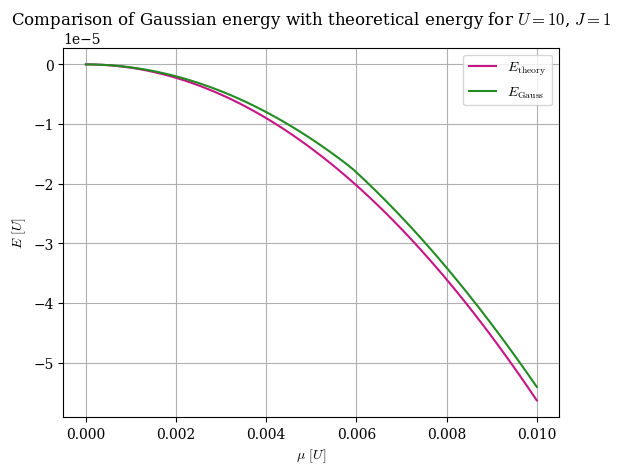

In [37]:
plt.plot(mu_vals, E_theory_list, label="$E_{\\text{theory}}$", color='mediumvioletred')
plt.plot(mu_vals, E_Gauss_list, label="$E_{\\text{Gauss}}$", color='forestgreen')
plt.title(r'Comparison of Gaussian energy with theoretical energy for $U = 10$, $J = 1$')
plt.xlabel(r'$\mu$ $[U]$')
plt.ylabel(r'$E$ $[U]$')
plt.grid()
plt.legend()